# Setup

In [1]:
import os
import time
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    f1_score, accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

In [2]:
CURRENT_DIR = os.getcwd()

if os.path.isdir(os.path.join(CURRENT_DIR, "data")):
    ROOT_DIR = CURRENT_DIR
elif os.path.isdir(os.path.join(CURRENT_DIR, "..", "data")):
    ROOT_DIR = os.path.abspath(os.path.join(CURRENT_DIR, ".."))
else:
    raise FileNotFoundError("Folder data/ tidak ditemukan. Jalankan notebook dari root project atau folder notebooks.")

DATA_DIR = os.path.join(ROOT_DIR, "data")
MODEL_DIR = os.path.join(ROOT_DIR, "models")
REPORT_DIR = os.path.join(ROOT_DIR, "reports")
FIGURE_DIR = os.path.join(REPORT_DIR, "figures")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

print("Root project:", ROOT_DIR)
print("Data directory:", DATA_DIR)

Root project: c:\Downloads\Sem 5\SUP\kagglecomp
Data directory: c:\Downloads\Sem 5\SUP\kagglecomp\data


# Read Data

In [3]:
train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
kaggle_test = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
sample_submission = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))
metadata_path = os.path.join(DATA_DIR, "metadata.csv")
metadata = pd.read_csv(metadata_path) if os.path.exists(metadata_path) else None

TARGET = "damage_grade"
ID_COL = "building_id"

print("Train:", train.shape)
print("Kaggle test:", kaggle_test.shape)
print("Sample submission:", sample_submission.shape)
if metadata is not None:
    print("Metadata:", metadata.shape)

display(train.head())

Train: (533465, 17)
Kaggle test: (228629, 16)
Sample submission: (228629, 2)
Metadata: (27, 3)


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


# Fitur

In [4]:
X = train.drop(columns=[TARGET, ID_COL], errors="ignore").copy()
y = train[TARGET].copy()

X_kaggle_test = kaggle_test.drop(columns=[ID_COL], errors="ignore").copy()

geo_cols = [col for col in ["district_id", "vdcmun_id", "ward_id"] if col in X.columns]
for col in geo_cols:
    X[col] = X[col].astype("string")
    if col in X_kaggle_test.columns:
        X_kaggle_test[col] = X_kaggle_test[col].astype("string")

X_kaggle_test = X_kaggle_test.reindex(columns=X.columns)

print("Jumlah fitur:", X.shape[1])
print("Jumlah kelas:", y.nunique())
print("Kelas target:", sorted(y.dropna().unique()))
display(y.value_counts().sort_index().to_frame("count"))

Jumlah fitur: 15
Jumlah kelas: 5
Kelas target: ['Grade 1', 'Grade 2', 'Grade 3', 'Grade 4', 'Grade 5']


,count
damage_grade,
Grade 1,55170
Grade 2,61080
Grade 3,95488
Grade 4,128691
Grade 5,193036


# Split Data

In [5]:
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("X_kaggle_test:", X_kaggle_test.shape)

print("\nProporsi kelas train:")
display(y_train.value_counts(normalize=True).sort_index().round(4))
print("\nProporsi kelas validasi:")
display(y_valid.value_counts(normalize=True).sort_index().round(4))

X_train: (426772, 15)
X_valid: (106693, 15)
X_kaggle_test: (228629, 15)

Proporsi kelas train:


damage_grade
Grade 1    0.1034
Grade 2    0.1145
Grade 3    0.1790
Grade 4    0.2412
Grade 5    0.3619
Name: proportion, dtype: float64


Proporsi kelas validasi:


damage_grade
Grade 1    0.1034
Grade 2    0.1145
Grade 3    0.1790
Grade 4    0.2412
Grade 5    0.3619
Name: proportion, dtype: float64

# Preprocessing

In [6]:
categorical_cols = X_train.select_dtypes(include=["object", "category", "string", "bool"]).columns.tolist()
numeric_cols = [col for col in X_train.columns if col not in categorical_cols]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=5))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_cols),
        ("cat", categorical_pipeline, categorical_cols)
    ],
    remainder="drop"
)

print("Fitur numerik:", len(numeric_cols))
print("Fitur kategorikal:", len(categorical_cols))

Fitur numerik: 4
Fitur kategorikal: 11


# Encoding XGBoost

In [7]:
label_encoder = LabelEncoder()
y_train_xgb = label_encoder.fit_transform(y_train)
y_valid_xgb = label_encoder.transform(y_valid)

print("Kelas asli:", label_encoder.classes_)
print("Label encoded untuk XGBoost:", np.unique(y_train_xgb))

Kelas asli: ['Grade 1' 'Grade 2' 'Grade 3' 'Grade 4' 'Grade 5']
Label encoded untuk XGBoost: [0 1 2 3 4]


# Model yang digunakan

In [8]:
models = {
    "LDA": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("svd", TruncatedSVD(n_components=30, random_state=42)),
        ("classifier", LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"))
    ]),
    "SVM": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", LinearSVC(C=1.0, class_weight="balanced", random_state=42, max_iter=3000))
    ]),
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(C=1.0, solver="saga", class_weight="balanced", max_iter=300, tol=1e-3, random_state=42))
    ]),
    "Decision Tree": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(max_depth=20, min_samples_leaf=5, class_weight="balanced", random_state=42))
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=2, class_weight="balanced", random_state=42, n_jobs=-1))
    ]),
    "XGBoost": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", XGBClassifier(objective="multi:softprob", eval_metric="mlogloss", n_estimators=150, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8, tree_method="hist", random_state=42, n_jobs=1))
    ]),
    "LightGBM": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", LGBMClassifier(objective="multiclass", n_estimators=150, learning_rate=0.1, num_leaves=31, class_weight="balanced", random_state=42, n_jobs=1, verbosity=-1))
    ])
}

print("Model yang akan dilatih:", list(models.keys()))

Model yang akan dilatih: ['LDA', 'SVM', 'Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'LightGBM']


# Training

In [9]:
def predict_labels(model, model_name, X_eval):
    pred = model.predict(X_eval)
    if model_name == "XGBoost":
        pred = np.asarray(pred).astype(int)
        return label_encoder.inverse_transform(pred)
    return pred

results = []
trained_models = {}
predictions = {}

for name, model in models.items():
    print(f"\nTraining {name}")
    start_train = time.time()
    try:
        if name == "XGBoost":
            model.fit(X_train, y_train_xgb)
        else:
            model.fit(X_train, y_train)

        y_pred = predict_labels(model, name, X_valid)
        elapsed = time.time() - start_train
        macro_f1 = f1_score(y_valid, y_pred, average="macro", zero_division=0)
        accuracy = accuracy_score(y_valid, y_pred)

        trained_models[name] = model
        predictions[name] = y_pred
        results.append({
            "Model": name,
            "Macro F1": macro_f1,
            "Accuracy": accuracy,
            "Training Time (s)": elapsed,
            "Status": "Success"
        })
        print(f"Macro F1: {macro_f1:.4f} | Accuracy: {accuracy:.4f} | Time: {elapsed:.1f}s")
    except Exception as error:
        results.append({
            "Model": name, "Macro F1": np.nan, "Accuracy": np.nan,
            "Training Time (s)": time.time() - start_train,
            "Status": f"Failed: {error}"
        })
        print(f"Training gagal untuk {name}: {error}")

results_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False, na_position="last").reset_index(drop=True)
display(results_df)


Training LDA
Macro F1: 0.3933 | Accuracy: 0.4644 | Time: 22.9s

Training SVM
Macro F1: 0.5024 | Accuracy: 0.5445 | Time: 175.3s

Training Logistic Regression
Macro F1: 0.5074 | Accuracy: 0.5390 | Time: 114.6s

Training Decision Tree
Macro F1: 0.4692 | Accuracy: 0.4917 | Time: 72.2s

Training Random Forest
Macro F1: 0.4683 | Accuracy: 0.5157 | Time: 75.8s

Training XGBoost
Macro F1: 0.4754 | Accuracy: 0.5447 | Time: 94.6s

Training LightGBM
Macro F1: 0.5214 | Accuracy: 0.5527 | Time: 88.7s


,Model,Macro F1,Accuracy,Training Time (s),Status
0,LightGBM,0.521414,0.552670,88.677513,Success
1,Logistic Regression,0.507444,0.538958,114.619070,Success
2,SVM,0.502413,0.544497,175.304540,Success
3,XGBoost,0.475364,0.544684,94.566746,Success
4,Decision Tree,0.469190,0.491654,72.215160,Success
5,Random Forest,0.468253,0.515657,75.778973,Success
6,LDA,0.393298,0.464445,22.934520,Success


# Perbandingan Macro F1

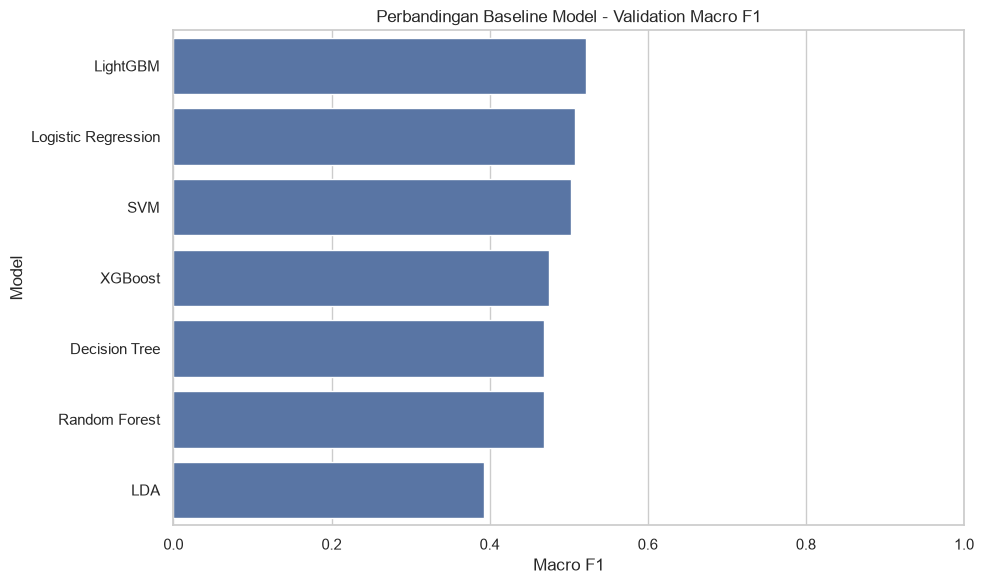

In [10]:
plot_results = results_df.dropna(subset=["Macro F1"]).copy()
if plot_results.empty:
    raise RuntimeError("Tidak ada model yang berhasil dilatih.")

plt.figure(figsize=(10, 6))
sns.barplot(data=plot_results, x="Macro F1", y="Model")
plt.title("Perbandingan Baseline Model - Validation Macro F1")
plt.xlabel("Macro F1")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "all_models_macro_f1.png"), dpi=150, bbox_inches="tight")
plt.show()

# Classification Report

In [11]:
for name, y_pred in predictions.items():
    print(f"\nClassification Report — {name}")
    print(classification_report(y_valid, y_pred, zero_division=0))


Classification Report — LDA
              precision    recall  f1-score   support

     Grade 1       0.50      0.61      0.55     11034
     Grade 2       0.25      0.15      0.19     12216
     Grade 3       0.28      0.16      0.20     19098
     Grade 4       0.35      0.40      0.37     25738
     Grade 5       0.61      0.72      0.66     38607

    accuracy                           0.46    106693
   macro avg       0.40      0.41      0.39    106693
weighted avg       0.43      0.46      0.44    106693


Classification Report — SVM
              precision    recall  f1-score   support

     Grade 1       0.51      0.77      0.62     11034
     Grade 2       0.33      0.31      0.32     12216
     Grade 3       0.40      0.37      0.38     19098
     Grade 4       0.49      0.47      0.48     25738
     Grade 5       0.74      0.69      0.71     38607

    accuracy                           0.54    106693
   macro avg       0.49      0.52      0.50    106693
weighted avg       

# Confusion Matrix

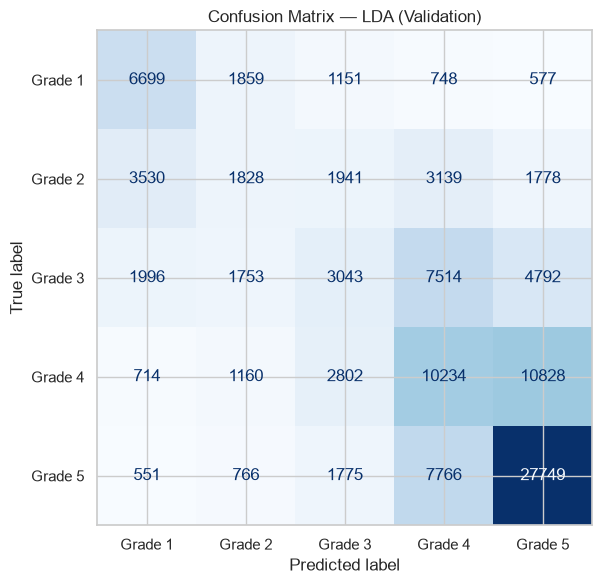

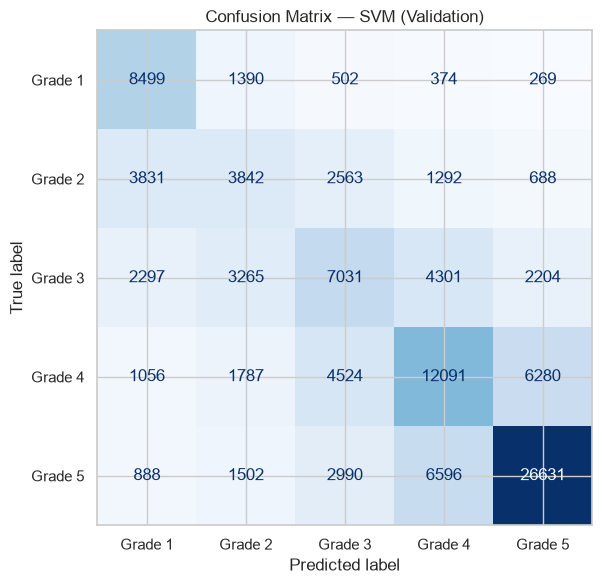

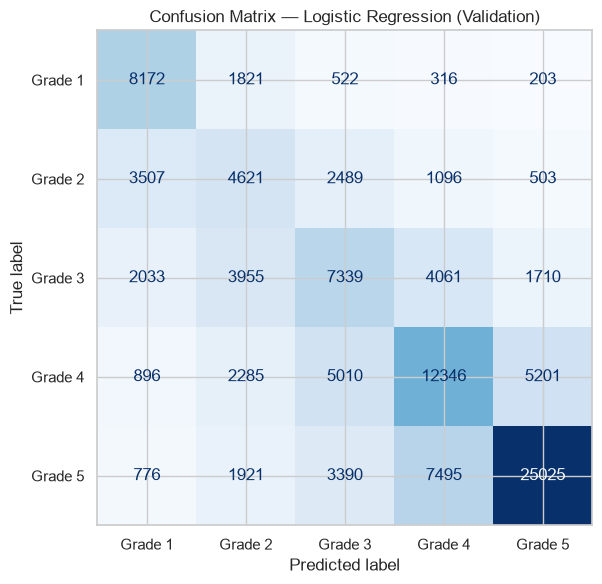

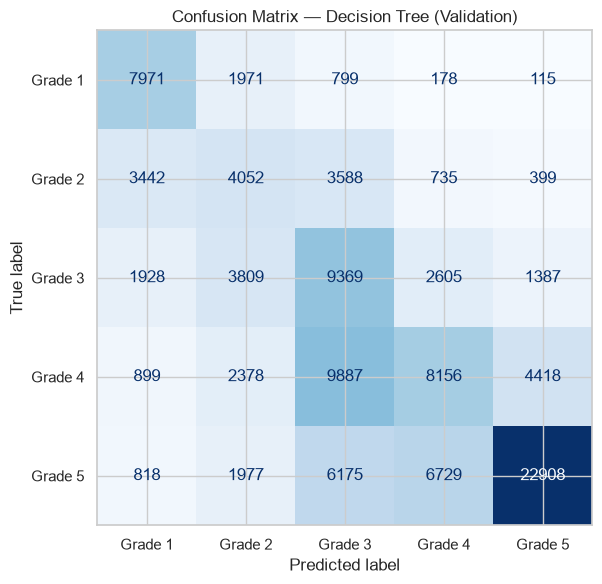

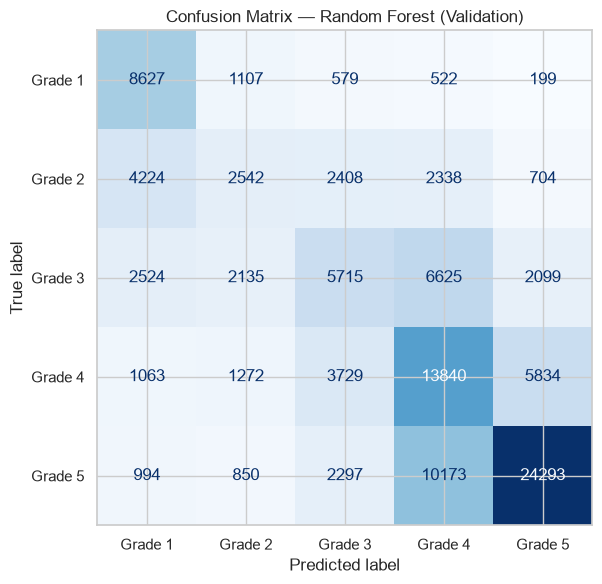

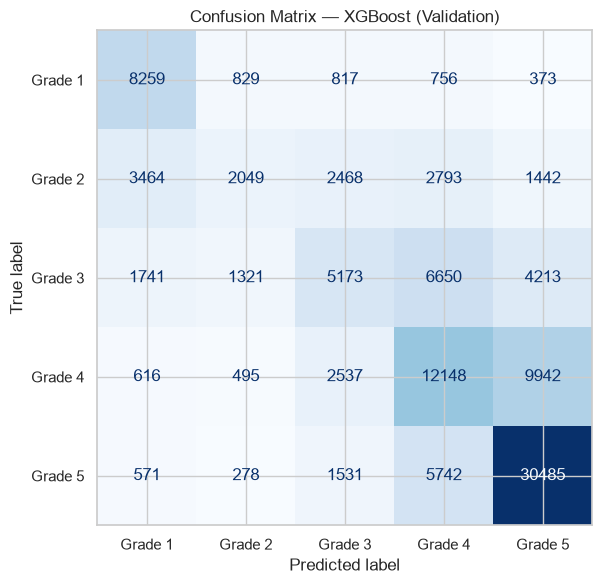

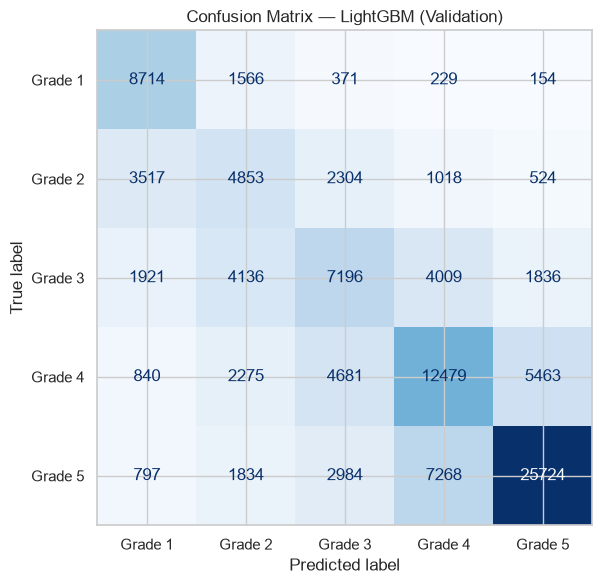

In [12]:
labels = sorted(y.unique())
for name, y_pred in predictions.items():
    cm = confusion_matrix(y_valid, y_pred, labels=labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    fig, ax = plt.subplots(figsize=(7, 6))
    disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"Confusion Matrix — {name} (Validation)")
    plt.tight_layout()
    safe_name = name.lower().replace(" ", "_")
    plt.savefig(os.path.join(FIGURE_DIR, f"confusion_matrix_{safe_name}.png"), dpi=150, bbox_inches="tight")
    plt.show()

# Base Model Terbaik

In [13]:
successful_results = results_df.dropna(subset=["Macro F1"])
if successful_results.empty:
    raise RuntimeError("Tidak ada model baseline yang berhasil.")

best_model_name = successful_results.iloc[0]["Model"]
best_baseline_model = trained_models[best_model_name]
baseline_f1 = float(successful_results.iloc[0]["Macro F1"])

print("Model baseline terbaik:", best_model_name)
print(f"Validation Macro F1: {baseline_f1:.4f}")

Model baseline terbaik: LightGBM
Validation Macro F1: 0.5214


# Hyperparameter Tuning

In [14]:
param_grids = {
    "LDA": {"svd__n_components": [20, 30]},
    "SVM": {"classifier__C": [0.5, 1.0]},
    "Logistic Regression": {"classifier__C": [0.5, 1.0]},
    "Decision Tree": {"classifier__max_depth": [15, 25], "classifier__min_samples_leaf": [2, 5]},
    "Random Forest": {"classifier__n_estimators": [100], "classifier__max_depth": [15, None], "classifier__min_samples_leaf": [2, 5]},
    "XGBoost": {"classifier__n_estimators": [100, 150], "classifier__max_depth": [4, 6]},
    "LightGBM": {"classifier__n_estimators": [100, 150], "classifier__num_leaves": [31, 50]}
}

best_model = trained_models[best_model_name]
best_params = {}
best_cv_f1 = None
start_tuning = time.time()

try:
    grid_search = GridSearchCV(
        estimator=clone(best_baseline_model),
        param_grid=param_grids[best_model_name],
        scoring="f1_macro",
        cv=2,
        n_jobs=1,
        verbose=2,
        refit=True,
        error_score="raise"
    )
    if best_model_name == "XGBoost":
        grid_search.fit(X_train, y_train_xgb)
    else:
        grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    best_params = grid_search.best_params_
    best_cv_f1 = float(grid_search.best_score_)
    print("Best parameters:", best_params)
    print(f"Best CV Macro F1: {best_cv_f1:.4f}")
except Exception as error:
    print("GridSearchCV gagal:", repr(error))
    print("Kembali menggunakan baseline model.")
    best_model = best_baseline_model

tuning_time = time.time() - start_tuning
print(f"Waktu tuning: {tuning_time / 60:.2f} menit")

Fitting 2 folds for each of 4 candidates, totalling 8 fits
[CV] END classifier__n_estimators=100, classifier__num_leaves=31; total time=  49.8s
[CV] END classifier__n_estimators=100, classifier__num_leaves=31; total time=  52.4s
[CV] END classifier__n_estimators=100, classifier__num_leaves=50; total time= 1.1min
[CV] END classifier__n_estimators=100, classifier__num_leaves=50; total time= 1.1min
[CV] END classifier__n_estimators=150, classifier__num_leaves=31; total time= 1.2min
[CV] END classifier__n_estimators=150, classifier__num_leaves=31; total time= 1.2min
[CV] END classifier__n_estimators=150, classifier__num_leaves=50; total time= 1.5min
[CV] END classifier__n_estimators=150, classifier__num_leaves=50; total time= 1.5min
Best parameters: {'classifier__n_estimators': 150, 'classifier__num_leaves': 50}
Best CV Macro F1: 0.5280
Waktu tuning: 10.58 menit


# Evaluasi Baseline vs Model Tuning

In [15]:
baseline_pred = predict_labels(best_baseline_model, best_model_name, X_valid)
final_pred = predict_labels(best_model, best_model_name, X_valid)

baseline_f1 = f1_score(y_valid, baseline_pred, average="macro", zero_division=0)
final_f1 = f1_score(y_valid, final_pred, average="macro", zero_division=0)

print(f"Baseline Macro F1: {baseline_f1:.4f}")
print(f"Final Macro F1:    {final_f1:.4f}")

if final_f1 < baseline_f1:
    print("Tuning tidak meningkatkan skor. Kembali ke baseline.")
    best_model = best_baseline_model
    final_pred = baseline_pred
    final_f1 = baseline_f1
    best_params = {}
else:
    print("Model hasil tuning dipertahankan.")

print("\nClassification report model final:")
print(classification_report(y_valid, final_pred, zero_division=0))

Baseline Macro F1: 0.5214
Final Macro F1:    0.5279
Model hasil tuning dipertahankan.

Classification report model final:
              precision    recall  f1-score   support

     Grade 1       0.56      0.79      0.65     11034
     Grade 2       0.34      0.41      0.37     12216
     Grade 3       0.41      0.39      0.40     19098
     Grade 4       0.51      0.49      0.50     25738
     Grade 5       0.77      0.66      0.71     38607

    accuracy                           0.56    106693
   macro avg       0.52      0.55      0.53    106693
weighted avg       0.57      0.56      0.56    106693



# Confusion Matrix Final Moel

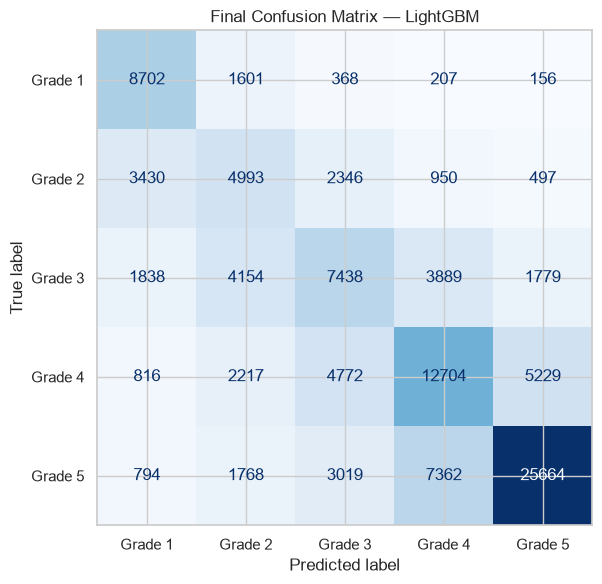

In [16]:
labels = sorted(y.unique())
cm = confusion_matrix(y_valid, final_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title(f"Final Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "final_confusion_matrix.png"), dpi=150, bbox_inches="tight")
plt.show()

# Simpan Model Terbaik

In [17]:
model_path = os.path.join(MODEL_DIR, "best_model.pkl")

model_bundle = {
    "model_name": best_model_name,
    "model": best_model,
    "label_encoder": label_encoder,
    "feature_columns": X.columns.tolist(),
    "target_name": TARGET,
    "id_column": ID_COL,
    "best_params": best_params,
    "baseline_macro_f1": float(baseline_f1),
    "validation_macro_f1": float(final_f1),
    "best_cv_macro_f1": best_cv_f1
}

with open(model_path, "wb") as file:
    pickle.dump(model_bundle, file)

print("Model berhasil disimpan:", model_path)
print("Model:", best_model_name)
print(f"Validation Macro F1: {final_f1:.4f}")

Model berhasil disimpan: c:\Downloads\Sem 5\SUP\kagglecomp\models\best_model.pkl
Model: LightGBM
Validation Macro F1: 0.5279


# Ringkasan Hasil

In [18]:
print("RINGKASAN MODELING")
print("Jumlah baseline berhasil:", len(trained_models), "dari", len(models))
print("Model terbaik:", best_model_name)
print(f"Baseline Macro F1: {baseline_f1:.4f}")
print(f"Final Validation Macro F1: {final_f1:.4f}")
print("Parameter tuning:", best_params)
print(f"Waktu tuning: {tuning_time / 60:.2f} menit")
print("Model tersimpan:", model_path)
print("\nRanking baseline:")
display(results_df[["Model", "Macro F1", "Accuracy", "Training Time (s)", "Status"]])

RINGKASAN MODELING
Jumlah baseline berhasil: 7 dari 7
Model terbaik: LightGBM
Baseline Macro F1: 0.5214
Final Validation Macro F1: 0.5279
Parameter tuning: {'classifier__n_estimators': 150, 'classifier__num_leaves': 50}
Waktu tuning: 10.58 menit
Model tersimpan: c:\Downloads\Sem 5\SUP\kagglecomp\models\best_model.pkl

Ranking baseline:


,Model,Macro F1,Accuracy,Training Time (s),Status
0,LightGBM,0.521414,0.552670,88.677513,Success
1,Logistic Regression,0.507444,0.538958,114.619070,Success
2,SVM,0.502413,0.544497,175.304540,Success
3,XGBoost,0.475364,0.544684,94.566746,Success
4,Decision Tree,0.469190,0.491654,72.215160,Success
5,Random Forest,0.468253,0.515657,75.778973,Success
6,LDA,0.393298,0.464445,22.934520,Success
